# Task 1 — FER2013 baseline: 3 feature types × 3 classifiers

**Goal.** Compare Logistic Regression, SVM and Random Forest on three feature representations
(HOG, dlib facial landmarks, PCA of raw pixels) on FER2013, and analyse which emotions are hard.

**Protocol (as required by the assignment).**
* `Training` split → fitting the models.
* `PublicTest` split (= *validation*) → hyperparameter / model selection (selection metric: macro-F1,
  because the classes are strongly imbalanced).
* `PrivateTest` split (= *test*) → used **once**, only for the final numbers of the selected configurations.

Reported metrics: accuracy, balanced accuracy, macro-F1 and confusion matrices.

> No class balancing or augmentation is used here on purpose: this is the *baseline*;
> those techniques are left for the creative challenge (Task 5), so their effect can be measured against these numbers.

Run this notebook from the `Assignment2_2026` folder, after `z_load_split_fer2013.ipynb`
(or with `data/fer2013.csv` present — the split is then made here).

In [1]:
import os, time, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report)

from src.features import (EMOTIONS, fer_pixels_to_images, hog_features,
                          landmark_features, pixel_features)

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA = Path("data")
FEAT_CACHE = DATA / "features"; FEAT_CACHE.mkdir(parents=True, exist_ok=True)
MODELS = Path("models"); MODELS.mkdir(exist_ok=True)
FIGS = Path("figures/task1"); FIGS.mkdir(parents=True, exist_ok=True)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

# Hyperparameters are searched on a stratified subsample of the training set to keep the
# RBF-SVM grid affordable on a laptop; the selected configuration is then refitted on the
# FULL training set. Set to None to tune on the full training set.
TUNE_SUBSAMPLE = 10000

## 1. Data: load the three splits

In [2]:
split_files = {s: DATA / f"fer2013_{s}.csv" for s in ["train", "validation", "test"]}
if not all(p.exists() for p in split_files.values()):
    # the raw file may be at data/fer2013.csv or data/fer/fer2013.csv
    raw = next(p for p in [DATA / "fer2013.csv", DATA / "fer" / "fer2013.csv"] if p.exists())
    df = pd.read_csv(raw)
    df[df.Usage == "Training"].to_csv(split_files["train"], index=False)
    df[df.Usage == "PublicTest"].to_csv(split_files["validation"], index=False)
    df[df.Usage == "PrivateTest"].to_csv(split_files["test"], index=False)

dfs = {s: pd.read_csv(p) for s, p in split_files.items()}
imgs = {s: fer_pixels_to_images(d["pixels"]) for s, d in dfs.items()}
ys = {s: d["emotion"].values.astype(int) for s, d in dfs.items()}

counts = pd.DataFrame({s: pd.Series(y).value_counts().sort_index() for s, y in ys.items()})
counts.index = EMOTIONS
counts["train %"] = (100 * counts["train"] / counts["train"].sum()).round(1)
counts

,train,validation,test,train %
Angry,3995,467,491,13.9
Disgust,436,56,55,1.5
Fear,4097,496,528,14.3
Happy,7215,895,879,25.1
Sad,4830,653,594,16.8
Surprise,3171,415,416,11.0
Neutral,4965,607,626,17.3


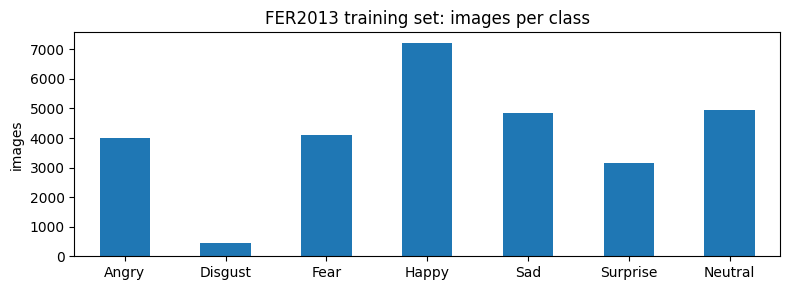

Imbalance ratio largest/smallest class: 16.5x


In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
counts["train"].plot.bar(ax=ax, color="tab:blue")
ax.set_title("FER2013 training set: images per class"); ax.set_ylabel("images")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIGS / "class_distribution.png", dpi=150); plt.show()
print(f"Imbalance ratio largest/smallest class: {counts['train'].max() / counts['train'].min():.1f}x")

## 2. Feature extraction

| Feature | Dim. | What it captures |
|---|---|---|
| **HOG** (9 orientations, 8×8 cells, 2×2 blocks) | 900 | local edge/gradient structure (wrinkles, mouth/eye shape); some robustness to illumination via block normalisation |
| **Landmarks** (dlib 68 points, baseline normalisation) | 136 | pure face geometry; no texture. dlib is run on the whole 48×48 patch as face box, as in the given baseline |
| **PCA** (on raw pixels in [0,1]) | chosen below | global appearance ("eigenfaces"); very sensitive to lighting, pose and alignment |

Features are cached in `data/features/` so the notebook can be re-run quickly.

In [4]:
def cached(name, fn):
    path = FEAT_CACHE / f"fer_{name}.npz"
    if path.exists():
        return dict(np.load(path))
    t = time.time()
    out = {s: fn(imgs[s]) for s in ["train", "validation", "test"]}
    np.savez_compressed(path, **out)
    print(f"{name}: extracted in {time.time() - t:.0f}s")
    return out

feats = {}
feats["HOG"] = cached("hog", hog_features)
feats["Landmarks"] = cached("landmarks", landmark_features)
pixels = cached("pixels", pixel_features)
for k, v in feats.items():
    print(k, v["train"].shape)

landmarks: extracted in 81s


OSError: [Errno 28] No space left on device

### PCA: choosing the number of components
The PCA is fitted on the **training pixels only** and then applied to validation and test.

In [ ]:
pca_full = PCA(random_state=RANDOM_STATE).fit(pixels["train"])
cum = np.cumsum(pca_full.explained_variance_ratio_)
N_PCA = int(np.searchsorted(cum, 0.95) + 1)   # 95 % of the pixel variance

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, len(cum) + 1), cum)
ax.axvline(N_PCA, ls="--", c="gray"); ax.set_xscale("log")
ax.set_xlabel("number of components"); ax.set_ylabel("cumulative explained variance")
ax.set_title(f"PCA on FER2013 pixels — 95% variance at {N_PCA} components")
plt.tight_layout(); plt.savefig(FIGS / "pca_variance.png", dpi=150); plt.show()

pca = PCA(n_components=N_PCA, random_state=RANDOM_STATE).fit(pixels["train"])
joblib.dump(pca, MODELS / "fer_pca.pkl")
feats["PCA"] = {s: pca.transform(pixels[s]).astype(np.float32) for s in pixels}
print("PCA features:", feats["PCA"]["train"].shape)

In [ ]:
# The first eigenfaces: what global appearance modes does PCA capture?
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
axes[0].imshow(pca.mean_.reshape(48, 48), cmap="gray"); axes[0].set_title("mean")
for i, ax in enumerate(axes[1:]):
    ax.imshow(pca.components_[i].reshape(48, 48), cmap="gray"); ax.set_title(f"PC{i+1}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.savefig(FIGS / "eigenfaces.png", dpi=150); plt.show()

## 3. Classifiers and hyperparameter selection on the validation split

* **Logistic Regression** — linear, multinomial; features standardised. Tuned: `C`.
* **SVM** — RBF kernel; features standardised. Tuned: `C` (`gamma='scale'`).
* **Random Forest** — 300 trees, `max_features='sqrt'`, entropy criterion (as in the baseline). Tuned: `max_depth`.

For every (feature, classifier) pair the value with the best **validation macro-F1** is selected,
then the model is refitted on the full training set.

In [ ]:
def make_model(name, **p):
    if name == "LogReg":
        return make_pipeline(StandardScaler(),
                             LogisticRegression(max_iter=3000, random_state=RANDOM_STATE, **p))
    if name == "SVM":
        return make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma="scale",
                                                   random_state=RANDOM_STATE, **p))
    if name == "RF":
        return RandomForestClassifier(n_estimators=300, max_features="sqrt", criterion="entropy",
                                      n_jobs=-1, random_state=RANDOM_STATE, **p)

GRIDS = {
    "LogReg": [{"C": c} for c in [0.001, 0.01, 0.1, 1.0]],
    "SVM":    [{"C": c} for c in [0.3, 1.0, 3.0, 10.0]],
    "RF":     [{"max_depth": d} for d in [11, 20, None]],
}

def metrics(y, p):
    return {"accuracy": accuracy_score(y, p),
            "balanced_accuracy": balanced_accuracy_score(y, p),
            "macro_f1": f1_score(y, p, average="macro")}

# stratified subsample of the training set used only for the hyperparameter search
rng = np.random.default_rng(RANDOM_STATE)
if TUNE_SUBSAMPLE and TUNE_SUBSAMPLE < len(ys["train"]):
    from sklearn.model_selection import train_test_split
    tune_idx, _ = train_test_split(np.arange(len(ys["train"])), train_size=TUNE_SUBSAMPLE,
                                   stratify=ys["train"], random_state=RANDOM_STATE)
else:
    tune_idx = np.arange(len(ys["train"]))
print("Tuning on", len(tune_idx), "training images")

In [ ]:
search_rows = []
for feat_name, F in feats.items():
    for clf_name, grid in GRIDS.items():
        for params in grid:
            t = time.time()
            m = make_model(clf_name, **params).fit(F["train"][tune_idx], ys["train"][tune_idx])
            r = metrics(ys["validation"], m.predict(F["validation"]))
            search_rows.append({"feature": feat_name, "classifier": clf_name,
                                "params": json.dumps(params), **r, "fit_s": time.time() - t})
            print(f"{feat_name:9s} {clf_name:6s} {str(params):22s} val macro-F1 = {r['macro_f1']:.3f}"
                  f"  ({time.time() - t:.0f}s)")

search = pd.DataFrame(search_rows)
search.to_csv(RESULTS / "task1_hyperparameter_search.csv", index=False)

In [ ]:
# best hyperparameters per (feature, classifier)
best_params = (search.sort_values("macro_f1", ascending=False)
                     .groupby(["feature", "classifier"]).head(1)
                     .set_index(["feature", "classifier"])["params"].map(json.loads).to_dict())
pd.Series({k: v for k, v in best_params.items()}, name="selected hyperparameters")

## 4. Refit selected configurations on the full training set; evaluate on validation and test

In [ ]:
results, preds, fitted = [], {}, {}
for (feat_name, clf_name), params in best_params.items():
    F = feats[feat_name]
    t = time.time()
    m = make_model(clf_name, **params).fit(F["train"], ys["train"])
    fit_s = time.time() - t
    fitted[(feat_name, clf_name)] = m
    joblib.dump(m, MODELS / f"fer_{feat_name.lower()}_{clf_name.lower()}.pkl")
    for split in ["validation", "test"]:
        p = m.predict(F[split])
        preds[(feat_name, clf_name, split)] = p
        results.append({"feature": feat_name, "classifier": clf_name, "split": split,
                        "params": json.dumps(params), **metrics(ys[split], p), "fit_s": fit_s})
    print(f"{feat_name:9s} {clf_name:6s} done ({fit_s:.0f}s)")

res = pd.DataFrame(results)
res.to_csv(RESULTS / "task1_results.csv", index=False)

In [ ]:
# Main results table (PrivateTest = test). Validation shown next to it to check for over-fitting
# of the selection.
tbl = res.pivot_table(index=["feature", "classifier"], columns="split",
                      values=["accuracy", "balanced_accuracy", "macro_f1"])
tbl = tbl.reorder_levels([1, 0], axis=1).sort_index(axis=1)[["validation", "test"]]
tbl.style.format("{:.3f}").background_gradient(cmap="Blues", subset=[("test", "macro_f1")])

In [ ]:
test_res = res[res.split == "test"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, metric in zip(axes, ["accuracy", "balanced_accuracy", "macro_f1"]):
    sns.barplot(data=test_res, x="feature", y=metric, hue="classifier", ax=ax,
                order=["HOG", "Landmarks", "PCA"], hue_order=["LogReg", "SVM", "RF"])
    ax.set_title(f"Test {metric.replace('_', ' ')}"); ax.set_ylim(0, 1)
    ax.axhline(1 / 7, ls=":", c="gray")   # chance level for 7 balanced classes
    if ax is not axes[0]: ax.get_legend().remove()
plt.tight_layout(); plt.savefig(FIGS / "test_metrics.png", dpi=150); plt.show()

# The "best" configuration is chosen on VALIDATION macro-F1 (the test split is never used for selection)
best_by_val = res[res.split == "validation"].sort_values("macro_f1", ascending=False).iloc[0]
best = test_res[(test_res.feature == best_by_val.feature) &
                (test_res.classifier == best_by_val.classifier)].iloc[0]
best_on_test = test_res.sort_values("macro_f1", ascending=False).iloc[0]
print(f"Selected on validation: {best.feature} + {best.classifier}  -> test macro-F1 = {best.macro_f1:.3f}")
print(f"(Highest test macro-F1: {best_on_test.feature} + {best_on_test.classifier} = {best_on_test.macro_f1:.3f})")

## 5. Confusion matrices (test split)
Rows are normalised (each row = recall per true class) so the minority class *Disgust* is readable;
the raw counts are written in each cell. Individual figures are saved in `figures/task1/` for the appendix.

In [ ]:
def plot_cm(y, p, title, ax):
    cm = confusion_matrix(y, p, labels=range(7))
    cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    annot = np.array([[f"{cmn[i,j]:.2f}\n({cm[i,j]})" for j in range(7)] for i in range(7)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=ax, annot_kws={"size": 7})
    ax.set_title(title, fontsize=10); ax.set_xlabel("predicted"); ax.set_ylabel("true")

fig, axes = plt.subplots(3, 3, figsize=(18, 17))
for i, feat_name in enumerate(["HOG", "Landmarks", "PCA"]):
    for j, clf_name in enumerate(["LogReg", "SVM", "RF"]):
        plot_cm(ys["test"], preds[(feat_name, clf_name, "test")], f"{feat_name} + {clf_name}", axes[i, j])
plt.tight_layout(); plt.savefig(FIGS / "confusion_matrices_all.png", dpi=120); plt.show()

for (feat_name, clf_name, split), p in preds.items():
    if split != "test": continue
    f, ax = plt.subplots(figsize=(6, 5))
    plot_cm(ys["test"], p, f"FER2013 test — {feat_name} + {clf_name}", ax)
    plt.tight_layout(); f.savefig(FIGS / f"cm_{feat_name}_{clf_name}.png", dpi=150); plt.close(f)

## 6. Which emotions are hardest? Per-class F1 on the test split

In [ ]:
per_class = []
for (feat_name, clf_name, split), p in preds.items():
    if split != "test": continue
    f1s = f1_score(ys["test"], p, average=None, labels=range(7))
    per_class.append(pd.Series(f1s, index=EMOTIONS, name=f"{feat_name} + {clf_name}"))
per_class = pd.DataFrame(per_class)
per_class.to_csv(RESULTS / "task1_per_class_f1.csv")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(per_class, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax)
ax.set_title("Per-class F1 on FER2013 test"); plt.tight_layout()
plt.savefig(FIGS / "per_class_f1.png", dpi=150); plt.show()

print("Mean F1 per emotion over the 9 models (hardest first):")
print(per_class.mean().sort_values().round(3).to_string())

In [ ]:
best_key = (best.feature, best.classifier)
print(f"Classification report — {best.feature} + {best.classifier} (test)")
print(classification_report(ys["test"], preds[(*best_key, "test")], target_names=EMOTIONS, digits=3))

## 7. Evidence: why are some samples hard?
Four checks on the best configuration:
1. **Misclassified examples** for each true class.
2. **Most confident mistakes** — candidates for *mislabelled* images.
3. **Image quality** — accuracy as a function of brightness and contrast.
4. **Degenerate images** in the training set (near-constant / non-face patches).

In [ ]:
best_model = fitted[best_key]
Xte = feats[best.feature]["test"]; yte = ys["test"]; pte = preds[(*best_key, "test")]

# confidence of the predicted class
if hasattr(best_model, "predict_proba"):
    conf = best_model.predict_proba(Xte).max(axis=1)
else:   # SVC without probabilities: use the decision-function margin
    conf = best_model.decision_function(Xte).max(axis=1)

def show_grid(idx, title, ncols=8):
    idx = list(idx)[:ncols * 2]
    if not idx: print("(none)"); return
    nrows = int(np.ceil(len(idx) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.9 * ncols, 2.3 * nrows), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, i in zip(axes.flat, idx):
        ax.imshow(imgs["test"][i], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"T:{EMOTIONS[yte[i]][:4]} P:{EMOTIONS[pte[i]][:4]}", fontsize=8,
                     color="green" if yte[i] == pte[i] else "red")
    fig.suptitle(title); plt.tight_layout(); return fig

rng = np.random.default_rng(0)
for c in range(7):
    wrong = np.where((yte == c) & (pte != c))[0]
    f = show_grid(rng.permutation(wrong)[:8], f"Misclassified true '{EMOTIONS[c]}' "
                  f"({len(wrong)}/{(yte == c).sum()} wrong)")
    if f: f.savefig(FIGS / f"misclassified_{EMOTIONS[c]}.png", dpi=120); plt.show()

In [ ]:
# Most confident errors: often mislabelled or ambiguous images
wrong = np.where(yte != pte)[0]
top_wrong = wrong[np.argsort(-conf[wrong])][:16]
f = show_grid(top_wrong, "Most confident mistakes (T = label in dataset, P = prediction)")
f.savefig(FIGS / "most_confident_mistakes.png", dpi=120); plt.show()

In [ ]:
# Image quality vs. correctness
brightness = imgs["test"].reshape(len(yte), -1).mean(axis=1)
contrast = imgs["test"].reshape(len(yte), -1).std(axis=1)
q = pd.DataFrame({"brightness": brightness, "contrast": contrast, "correct": yte == pte})
q["brightness bin"] = pd.qcut(q.brightness, 5, labels=["very dark", "dark", "mid", "bright", "very bright"])
q["contrast bin"] = pd.qcut(q.contrast, 5, labels=["very low", "low", "mid", "high", "very high"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
q.groupby("brightness bin", observed=True).correct.mean().plot.bar(ax=axes[0], color="tab:blue")
q.groupby("contrast bin", observed=True).correct.mean().plot.bar(ax=axes[1], color="tab:orange")
axes[0].set_ylabel("test accuracy"); axes[0].set_title("Accuracy per brightness quintile")
axes[1].set_title("Accuracy per contrast quintile")
for ax in axes: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIGS / "accuracy_vs_quality.png", dpi=150); plt.show()

f = show_grid(np.argsort(brightness)[:8].tolist() + np.argsort(-brightness)[:8].tolist(),
              "Darkest (top) and brightest (bottom) test images")
f.savefig(FIGS / "extreme_lighting.png", dpi=120); plt.show()

In [ ]:
# Degenerate training images: (near-)constant patches carry no facial information
std_tr = imgs["train"].reshape(len(ys["train"]), -1).std(axis=1)
degenerate = np.where(std_tr < 5)[0]
print(f"{len(degenerate)} training images with pixel std < 5 (practically blank)")
print(pd.Series(ys["train"][degenerate]).map(dict(enumerate(EMOTIONS))).value_counts().to_string())
if len(degenerate):
    fig, axes = plt.subplots(1, min(8, len(degenerate)), figsize=(14, 2.2), squeeze=False)
    for ax, i in zip(axes.flat, degenerate[:8]):
        ax.imshow(imgs["train"][i], cmap="gray", vmin=0, vmax=255)
        ax.set_title(EMOTIONS[ys["train"][i]], fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.savefig(FIGS / "degenerate_train_images.png", dpi=120); plt.show()

## 8. Save the selection for Task 2

In [ ]:
# Best feature = feature of the configuration with the highest VALIDATION macro-F1
# (selection must not use the test split).
val = res[res.split == "validation"]
feature_rank = val.groupby("feature").macro_f1.max().sort_values(ascending=False)
selection = {"best_feature": feature_rank.index[0],
             "best_classifier": best_by_val.classifier,
             "feature_ranking_val_macro_f1": feature_rank.round(4).to_dict(),
             "n_pca_components": N_PCA,
             "best_params": {f"{k[0]}|{k[1]}": v for k, v in best_params.items()}}
json.dump(selection, open(RESULTS / "task1_selection.json", "w"), indent=2)
selection

## 9. Observations (to be completed by the group)

Use the tables and figures above to answer the report questions; write these in your own words.

* **Which classifier performs best, and why?** Compare across rows of the results table; relate it to
  model capacity (linear vs. kernel vs. trees) and the dimensionality/type of each feature.
* **Which features work best?** Compare HOG / Landmarks / PCA for the same classifier.
  Think about what each representation can and cannot see (texture vs. geometry vs. global appearance).
* **Which emotions are most difficult?** See the per-class F1 heatmap and the confusion matrices
  (which pairs get confused?). Consider class frequency (Disgust ≈ 1.5 % of training data) and
  visual similarity (Fear vs. Surprise vs. Sad).
* **Evidence:** refer to the misclassified examples, most confident mistakes (label noise?),
  accuracy vs. brightness/contrast and the blank training images.